# SciBERT: contexto + documento citado (A/B)

- Contexto: solo el contexto de cita.
- A: contexto de cita + título + abstract del citado.
- B: contexto de cita + Top-3 chunks del citado con su sección.

Librerías necesarias para ejecutar este notebook (Python 3.12):

- torch 2.10.0
- transformers 5.20.2
- numpy 2.4.2
- pandas 3.1.0
- scikit-learn 1.8.0
- matplotlib 3.10.8
- mlflow 3.17.2 o mlflow-skinny 3.17.0(para conexión a servidor remoto)

In [4]:
import os
os.environ.setdefault('MLFLOW_IP','50.17.116.166:8080')
os.environ.setdefault('MLFLOW_EXPERIMENTO','consolidado')
os.environ.get('MLFLOW_IP'),os.environ.get('MLFLOW_EXPERIMENTO')

('50.17.116.166:8080', 'consolidado')

In [5]:
from pathlib import Path
import hashlib, json, os, re, time, platform
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from transformers.utils import logging as hf_logging
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display
import mlflow

hf_logging.set_verbosity_error()
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'dataset/train.jsonl').exists())
DATA = ROOT/'dataset'
RUN_NAME = os.environ.get('RUN_NAME') or datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
OUT = ROOT/'mlruns/scibert_ab'/RUN_NAME
OUT.mkdir(parents=True, exist_ok=True)
LABELS = ['Background','Uses','Comparison','Extends','Motivation','Future Work','Evidence','Originator','Further Reading']
K = len(LABELS)
LABEL2ID = {l:i for i,l in enumerate(LABELS)}
MODEL_NAME = 'allenai/scibert_scivocab_uncased'
STRATEGIES = ['contexto','A','B']
SEEDS = [42, 43, 44]
HP = {'lr':2e-5,'epochs':5,'patience':2,'batch_size':8,'grad_accum':2,'eval_batch_size':32,'warmup_ratio':0.1,'weight_decay':0.01,'max_length':512,'max_grad_norm':1.0}
SMOKE = os.environ.get('SMOKE') == '1'
if SMOKE:
    SEEDS, HP = SEEDS[:1], {**HP,'epochs':1}
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
AMP = DEVICE.type == 'cuda'
VERSIONS = {p:version(p) for p in ['torch','transformers','numpy','pandas','scikit-learn','mlflow-skinny']}
display(pd.Series({**VERSIONS,'python':platform.python_version(),'device':str(DEVICE),'run':RUN_NAME}, name='valor').to_frame())
if os.environ.get('MLFLOW_IP'):  # servidor de MLflow: MLFLOW_IP=ip:puerto y, opcional, MLFLOW_EXPERIMENTO
    mlflow.set_tracking_uri('http://' + os.environ['MLFLOW_IP'])
    mlflow.set_experiment(os.environ.get('MLFLOW_EXPERIMENTO', 'EvidenCite-SciBERT-AB'))
else:  # sin servidor, las llamadas a mlflow no hacen nada
    from unittest.mock import MagicMock
    mlflow = MagicMock()
    mlflow.active_run().info.run_id = None

,valor
torch,2.11.0+cu130
transformers,5.20.2
numpy,2.1.3
pandas,2.2.3
scikit-learn,1.6.1
mlflow-skinny,3.17.2
python,3.13.16
device,cuda
run,20261025T205925Z


In [6]:
splits = {s:[json.loads(line) for line in (DATA/f'{s}.jsonl').read_text().splitlines() if line.strip()] for s in ['train','dev','test']}
if SMOKE:
    splits = {s:rows[:64] for s,rows in splits.items()}
hashes = {s:hashlib.sha256((DATA/f'{s}.jsonl').read_bytes()).hexdigest() for s in splits}
assert all(r['label'] in LABELS for rows in splits.values() for r in rows)
for a,b in [('train','dev'),('train','test'),('dev','test')]:
    assert not ({r['citing_paper']['id'] for r in splits[a]} & {r['citing_paper']['id'] for r in splits[b]}), f'Solapamiento {a}/{b}'
y = {s:np.array([r['label'] for r in rows]) for s,rows in splits.items()}
ids = {s:np.array([LABEL2ID[l] for l in labels]) for s,labels in y.items()}
groups_test = np.array([r['citing_paper']['id'] for r in splits['test']])
counts = pd.DataFrame({s:pd.Series(labels).value_counts() for s,labels in y.items()}).reindex(LABELS).fillna(0).astype(int)
display(counts)
train_counts = np.bincount(ids['train'], minlength=K)
CLASS_WEIGHTS = torch.tensor(len(ids['train'])/(K*np.maximum(train_counts,1)), dtype=torch.float32)
manifest = {'sha256':hashes,'versions':VERSIONS,'python':platform.python_version(),'device':str(DEVICE),'model':MODEL_NAME,'labels':LABELS,'seeds':SEEDS,'hp':HP,'smoke':SMOKE,'class_counts':counts.to_dict(),'class_weights':dict(zip(LABELS,CLASS_WEIGHTS.tolist()))}
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')

,train,dev,test
Background,612,113,149
Uses,556,172,167
Comparison,422,129,121
Extends,149,29,20
Motivation,85,28,29
Future Work,8,2,0
Evidence,156,0,0
Originator,26,0,0
Further Reading,241,18,0


2083

In [7]:
def section(name):
    return '' if not name or name == 'Unknown Section' else f'[{name}] '

def citing_text(r):
    return section(r['citing_paper']['rhetorical_section']) + r['citation_context']

def cited_text(r, strategy):
    cited = r['cited_paper']
    if strategy == 'A':
        return f"{cited['title']}. {cited['abstract']}"
    chunks = sorted(cited['retrieved_chunks'], key=lambda c:c.get('rank',999))[:3]
    return ' '.join(section(c['section_heading']) + c['text'] for c in chunks)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def encode(rows, strategy, truncate=True):
    first = [citing_text(r) for r in rows]
    if strategy == 'contexto':
        return tokenizer(first, truncation=truncate, max_length=HP['max_length'] if truncate else None)
    second = [cited_text(r, strategy) for r in rows]
    return tokenizer(first, second, truncation='longest_first' if truncate else False, max_length=HP['max_length'] if truncate else None)

encoded, length_stats = {}, []
for strategy in STRATEGIES:
    encoded[strategy] = {}
    for s, rows in splits.items():
        encoded[strategy][s] = encode(rows, strategy)
        full = np.array([len(x) for x in encode(rows, strategy, truncate=False)['input_ids']])
        length_stats.append({'estrategia':strategy,'split':s,'media':full.mean(),'p50':np.percentile(full,50),'p95':np.percentile(full,95),'max':full.max(),'truncados_%':100*(full>HP['max_length']).mean()})
length_stats = pd.DataFrame(length_stats)
display(length_stats.round(1))
length_stats.to_csv(OUT/'token_lengths.csv', index=False)

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/228k [00:00<?, ?B/s]

,estrategia,split,media,p50,p95,max,truncados_%
0,contexto,train,128.2,118.0,216.0,662,0.2
1,contexto,dev,114.1,109.0,176.5,244,0.0
2,contexto,test,114.5,109.5,184.8,236,0.0
3,A,train,335.0,323.0,521.3,910,5.5
4,A,dev,273.8,291.0,410.0,519,0.2
5,A,test,299.6,309.5,485.2,567,2.3
6,B,train,528.7,508.0,689.0,2930,47.4
7,B,dev,499.1,496.0,604.5,764,38.1
8,B,test,500.1,513.0,616.2,788,50.2


In [8]:
def make_loader(enc, labels, shuffle, seed):
    items = [{**{k:enc[k][i] for k in enc.keys()}, 'labels':int(labels[i])} for i in range(len(labels))]
    return DataLoader(items, batch_size=HP['batch_size'] if shuffle else HP['eval_batch_size'], shuffle=shuffle,
                      generator=torch.Generator().manual_seed(seed), collate_fn=lambda b:tokenizer.pad(b, pad_to_multiple_of=64, return_tensors='pt'))

def predict_proba(model, loader):
    model.eval(); out = []
    with torch.no_grad():
        for batch in loader:
            batch = {k:v.to(DEVICE) for k,v in batch.items() if k != 'labels'}
            with torch.autocast('cuda', dtype=torch.float16, enabled=AMP):
                logits = model(**batch).logits
            out.append(torch.softmax(logits.float(), -1).cpu())
    return torch.cat(out).numpy()

def metrics(truth, pred):
    return {'accuracy':accuracy_score(truth,pred),'f1_macro_9':f1_score(truth,pred,labels=LABELS,average='macro',zero_division=0),
            'f1_macro_present':f1_score(truth,pred,labels=sorted(set(truth)),average='macro',zero_division=0),
            'f1_weighted':f1_score(truth,pred,average='weighted',zero_division=0)}

def train_run(strategy, seed):
    torch.manual_seed(seed); np.random.seed(seed)
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=K, id2label=dict(enumerate(LABELS)), label2id=LABEL2ID).to(DEVICE)
    train_loader = make_loader(encoded[strategy]['train'], ids['train'], True, seed)
    dev_loader = make_loader(encoded[strategy]['dev'], ids['dev'], False, seed)
    test_loader = make_loader(encoded[strategy]['test'], ids['test'], False, seed)
    updates = -(-len(train_loader)//HP['grad_accum']) * HP['epochs']
    optimizer = torch.optim.AdamW(model.parameters(), lr=HP['lr'], weight_decay=HP['weight_decay'])
    scheduler = get_linear_schedule_with_warmup(optimizer, int(HP['warmup_ratio']*updates), updates)
    loss_fn = torch.nn.CrossEntropyLoss(weight=CLASS_WEIGHTS.to(DEVICE))
    scaler = torch.amp.GradScaler('cuda', enabled=AMP)
    best_score, best_state, best_epoch, wait, history = -1.0, None, 0, 0, []
    start = time.perf_counter()
    for epoch in range(1, HP['epochs']+1):
        model.train(); total = torch.zeros((), device=DEVICE)
        for step, batch in enumerate(train_loader):
            batch = {k:v.to(DEVICE) for k,v in batch.items()}
            labels = batch.pop('labels')
            with torch.autocast('cuda', dtype=torch.float16, enabled=AMP):
                logits = model(**batch).logits
            loss = loss_fn(logits.float(), labels)
            scaler.scale(loss/HP['grad_accum']).backward()
            total += loss.detach()
            if (step+1) % HP['grad_accum'] == 0 or step+1 == len(train_loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), HP['max_grad_norm'])
                scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True); scheduler.step()
        dev_scores = metrics(y['dev'], np.array(LABELS)[predict_proba(model, dev_loader).argmax(1)])
        history.append({'epoch':epoch,'train_loss':total.item()/len(train_loader),**{f'dev_{k}':v for k,v in dev_scores.items()},'seconds':time.perf_counter()-start})
        print(strategy, seed, history[-1])
        if dev_scores['f1_macro_9'] > best_score:
            best_score, best_epoch, wait = dev_scores['f1_macro_9'], epoch, 0
            best_state = {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= HP['patience']:
                break
    train_seconds = time.perf_counter() - start
    model.load_state_dict(best_state)
    start = time.perf_counter()
    proba = predict_proba(model, test_loader)
    latency = (time.perf_counter()-start)/len(ids['test'])
    return model, proba, history, best_epoch, best_score, train_seconds, latency

In [9]:
results, histories, probas = [], {}, {}
best_dev = {}
for strategy in STRATEGIES:
    for seed in SEEDS:
        key = f'{strategy}_s{seed}'
        if (OUT/f'{key}.json').exists():
            saved = json.loads((OUT/f'{key}.json').read_text())
            results.append(saved['result']); histories[key] = saved['history']
            probas[key] = pd.read_csv(OUT/f'predictions_{key}.csv')[LABELS].to_numpy()
            continue
        with mlflow.start_run(run_name=key):
            mlflow.log_params({**HP,'strategy':strategy,'seed':seed,'model':MODEL_NAME,'selection_metric':'dev_f1_macro_9','smoke':SMOKE})
            model, proba, history, best_epoch, best_score, train_seconds, latency = train_run(strategy, seed)
            for h in history:
                mlflow.log_metrics({k:v for k,v in h.items() if k != 'epoch'}, step=h['epoch'])
            pred = np.array(LABELS)[proba.argmax(1)]
            test_scores = metrics(y['test'], pred)
            result = {'strategy':strategy,'seed':seed,'best_epoch':best_epoch,'dev_f1_macro_9':best_score,**{f'test_{k}':v for k,v in test_scores.items()},
                      'train_seconds':train_seconds,'latency_ms':1000*latency,'run_id':mlflow.active_run().info.run_id}
            mlflow.log_metrics({k:v for k,v in result.items() if k.startswith('test_') or k in ['train_seconds','latency_ms','best_epoch']})
            frame = pd.DataFrame(proba, columns=LABELS)
            frame.insert(0,'prediction',pred); frame.insert(0,'truth',y['test']); frame.insert(0,'citing_paper_id',groups_test)
            frame.insert(0,'instance_id',[r['instance_id'] for r in splits['test']])
            frame.to_csv(OUT/f'predictions_{key}.csv', index=False)
            mlflow.log_artifact(str(OUT/f'predictions_{key}.csv'))
            (OUT/f'{key}.json').write_text(json.dumps({'result':result,'history':history},indent=2),encoding='utf-8')
            if not SMOKE and best_score > best_dev.get(strategy,-1.0):
                best_dev[strategy] = best_score
                target = ROOT/'models'/{'A':'baseline_config_a','B':'baseline_config_b'}.get(strategy,'scibert_contexto')
                model.save_pretrained(target); tokenizer.save_pretrained(target)
            results.append(result); histories[key] = history; probas[key] = proba
            del model
            if DEVICE.type == 'mps': torch.mps.empty_cache()
            if DEVICE.type == 'cuda': torch.cuda.empty_cache()
results = pd.DataFrame(results)
display(results.round(4))
results.to_csv(OUT/'runs.csv', index=False)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  442MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  442MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

🏃 View run B_s43 at: http://50.17.116.166:8080/#/experiments/1/runs/5d002a0e177a4d83a6ccf465bb7f4c9d
🧪 View experiment at: http://50.17.116.166:8080/#/experiments/1


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

B 44 {'epoch': 1, 'train_loss': 1.8435569384419326, 'dev_accuracy': 0.5112016293279023, 'dev_f1_macro_9': 0.3392338325365418, 'dev_f1_macro_present': 0.4361577846898394, 'dev_f1_weighted': 0.4935342352846324, 'seconds': 76.60833904800029}
B 44 {'epoch': 2, 'train_loss': 1.0763336614514074, 'dev_accuracy': 0.670061099796334, 'dev_f1_macro_9': 0.3910903204520616, 'dev_f1_macro_present': 0.5028304120097935, 'dev_f1_weighted': 0.6513080008556036, 'seconds': 152.15808246200004}
B 44 {'epoch': 3, 'train_loss': 0.7220001761794935, 'dev_accuracy': 0.6517311608961304, 'dev_f1_macro_9': 0.40194760392278933, 'dev_f1_macro_present': 0.5167897764721577, 'dev_f1_weighted': 0.6522805340967655, 'seconds': 227.8784168090001}
B 44 {'epoch': 4, 'train_loss': 0.5175419259578624, 'dev_accuracy': 0.6232179226069247, 'dev_f1_macro_9': 0.4081443486839925, 'dev_f1_macro_present': 0.5247570197365619, 'dev_f1_weighted': 0.6335388851309103, 'seconds': 303.2145084460003}
B 44 {'epoch': 5, 'train_loss': 0.417231945

,strategy,seed,best_epoch,dev_f1_macro_9,test_accuracy,test_f1_macro_9,test_f1_macro_present,test_f1_weighted,train_seconds,latency_ms,run_id
0,contexto,42,3,0.5281,0.6152,0.2629,0.4732,0.6099,230.3424,3.9050,19ae5049d73e4260be7a6c8564dd5ef6
1,contexto,43,5,0.4983,0.5967,0.2668,0.4803,0.6006,192.7895,3.5232,8f929bacdc864522a6c8f8a500683f91
2,contexto,44,5,0.4912,0.5844,0.2649,0.4767,0.5842,179.0417,3.5959,dfb5629afddd42568722710f0c655fcd
3,A,42,5,0.4878,0.5844,0.2556,0.4600,0.5923,347.2041,7.6144,3d8c7c7af8e34a4a9540e4ba70530131
4,A,43,5,0.5000,0.5905,0.2573,0.4632,0.5934,347.8019,7.6677,0ca74c7259e34d4f95c4e5f7aba87688
5,A,44,4,0.5040,0.5720,0.2814,0.5066,0.5946,345.8514,7.6983,4c1c8596d6d647d5af9950ac3ceb5a90
6,B,42,5,0.4027,0.5741,0.2553,0.4595,0.5737,378.3863,8.7718,3862d5ae14e049438f6d002398182f28
7,B,43,5,0.4223,0.5864,0.2632,0.4738,0.5955,379.1659,8.8536,5d002a0e177a4d83a6ccf465bb7f4c9d
8,B,44,5,0.4103,0.5700,0.2569,0.4623,0.5751,379.2223,8.8391,1dc04bcfc417442188d6c3b53a5efccd


In [10]:
def tfidf_text(row, strategy):
    context = re.sub(r'</?cite>', '', row['citation_context'])
    cited = row['cited_paper']
    evidence = [cited['title'], cited['abstract']] if strategy=='A' else [c['text'] for c in sorted(cited['retrieved_chunks'],key=lambda c:c.get('rank',999))[:3]]
    return '\n'.join([context,*evidence])

TFIDF_CONFIGS = [{'config':'r1','ngram_max':1,'min_df':1,'C':0.5},{'config':'r2','ngram_max':2,'min_df':2,'C':1.0},{'config':'r3','ngram_max':2,'min_df':3,'C':2.0}]
tfidf_preds, tfidf_rows = {}, []
for strategy in ['A','B']:
    X = {s:[tfidf_text(r,strategy) for r in rows] for s,rows in splits.items()}
    best = None
    for config in TFIDF_CONFIGS:
        model = Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,config['ngram_max']),min_df=config['min_df'],max_features=100000,sublinear_tf=True)),
                          ('classifier',LogisticRegression(C=config['C'],class_weight='balanced',solver='lbfgs',max_iter=2000,random_state=42))]).fit(X['train'],y['train'])
        score = metrics(y['dev'], model.predict(X['dev']))['f1_macro_9']
        if best is None or score > best[0]:
            best = (score, config['config'], model)
    tfidf_preds[f'tfidf_{strategy}'] = best[2].predict(X['test'])
    tfidf_rows.append({'modelo':f'tfidf_{strategy}','config':best[1],**metrics(y['test'], tfidf_preds[f'tfidf_{strategy}'])})
display(pd.DataFrame(tfidf_rows).round(4))

,modelo,config,accuracy,f1_macro_9,f1_macro_present,f1_weighted
0,tfidf_A,r3,0.3745,0.1663,0.2993,0.4049
1,tfidf_B,r3,0.3045,0.1286,0.2315,0.3413


In [11]:
summary = results.groupby('strategy')[['test_accuracy','test_f1_macro_9','test_f1_macro_present','test_f1_weighted','train_seconds','latency_ms']].agg(['mean','std']).reindex(STRATEGIES)
display(summary.round(4))
summary.to_csv(OUT/'summary.csv')
per_class = pd.DataFrame({strategy:np.mean([f1_score(y['test'], np.array(LABELS)[probas[f'{strategy}_s{seed}'].argmax(1)], labels=LABELS, average=None, zero_division=0) for seed in SEEDS], axis=0) for strategy in STRATEGIES}, index=LABELS)
for name, pred in tfidf_preds.items():
    per_class[name] = f1_score(y['test'], pred, labels=LABELS, average=None, zero_division=0)
per_class['soporte_test'] = counts['test']
display(per_class.round(4))
per_class.to_csv(OUT/'f1_per_class.csv')

test_accuracy         test_f1_macro_9         test_f1_macro_present  \
                  mean     std            mean     std                  mean   
strategy                                                                       
contexto        0.5988  0.0155          0.2649  0.0020                0.4767   
A               0.5823  0.0094          0.2648  0.0145                0.4766   
B               0.5768  0.0086          0.2585  0.0042                0.4652   

                 test_f1_weighted         train_seconds          latency_ms  \
             std             mean     std          mean      std       mean   
strategy                                                                      
contexto  0.0036           0.5982  0.0130      200.7245  26.5549     3.6747   
A         0.0260           0.5935  0.0012      346.9525   0.9993     7.6601   
B         0.0076           0.5814  0.0122      378.9249   0.4672     8.8215   

                  
             std  
strategy          
contexto  0.2028  
A         0.0425  
B         0.0437

,contexto,A,B,tfidf_A,tfidf_B,soporte_test
Background,0.6909,0.6834,0.6884,0.4195,0.4401,149
Uses,0.6062,0.6027,0.5850,0.5103,0.3764,167
Comparison,0.6270,0.6159,0.5895,0.3626,0.2995,121
Extends,0.2921,0.2811,0.2721,0.0789,0.0000,20
Motivation,0.1676,0.1999,0.1911,0.1250,0.0417,29
Future Work,0.0000,0.0000,0.0000,0.0000,0.0000,0
Evidence,0.0000,0.0000,0.0000,0.0000,0.0000,0
Originator,0.0000,0.0000,0.0000,0.0000,0.0000,0
Further Reading,0.0000,0.0000,0.0000,0.0000,0.0000,0


In [12]:
def macro_f1(t, p):
    cm = np.bincount(t*K+p, minlength=K*K).reshape(K,K)
    tp = np.diag(cm); denom = cm.sum(0) + cm.sum(1)
    return np.where(denom>0, 2*tp/np.maximum(denom,1), 0.0).mean()

preds = {strategy:[probas[f'{strategy}_s{seed}'].argmax(1) for seed in SEEDS] for strategy in STRATEGIES}
preds.update({name:[np.array([LABEL2ID[l] for l in p])] for name,p in tfidf_preds.items()})

def paired_bootstrap(model, reference, by_paper=False, n=10000, seed=0):
    rng = np.random.default_rng(seed); truth = ids['test']
    papers = np.unique(groups_test); members = [np.where(groups_test==g)[0] for g in papers]
    observed = np.mean([macro_f1(truth,p) for p in preds[model]]) - np.mean([macro_f1(truth,p) for p in preds[reference]])
    diffs = np.empty(n)
    for i in range(n):
        idx = np.concatenate([members[j] for j in rng.integers(0,len(papers),len(papers))]) if by_paper else rng.integers(0,len(truth),len(truth))
        diffs[i] = np.mean([macro_f1(truth[idx],p[idx]) for p in preds[model]]) - np.mean([macro_f1(truth[idx],p[idx]) for p in preds[reference]])
    low, high = np.percentile(diffs,[2.5,97.5])
    return observed, low, high, (diffs<=0).mean()

COMPARISONS = [('B','A'),('A','contexto'),('B','contexto'),('A','tfidf_A'),('B','tfidf_B'),('A','tfidf_B'),('B','tfidf_A')]
rows = []
for model, reference in COMPARISONS:
    delta, low, high, p = paired_bootstrap(model, reference)
    _, plow, phigh, pp = paired_bootstrap(model, reference, by_paper=True)
    rows.append({'modelo':model,'referencia':reference,'delta_f1_macro_9':delta,'ic95_inf':low,'ic95_sup':high,'p':p,'supera':low>0,
                 'ic95_inf_por_paper':plow,'ic95_sup_por_paper':phigh,'p_por_paper':pp})
bootstrap = pd.DataFrame(rows)
display(bootstrap.round(4))
bootstrap.to_csv(OUT/'bootstrap.csv', index=False)

,modelo,referencia,delta_f1_macro_9,ic95_inf,ic95_sup,p,supera,ic95_inf_por_paper,ic95_sup_por_paper,p_por_paper
0,B,A,-0.0063,-0.0183,0.0054,0.8519,False,-0.0142,0.0033,0.9092
1,A,contexto,-0.0001,-0.0175,0.0173,0.4794,False,-0.0181,0.0165,0.5079
2,B,contexto,-0.0064,-0.0220,0.0092,0.7791,False,-0.0222,0.0082,0.7928
3,A,tfidf_A,0.0985,0.0649,0.1307,0.0000,True,0.0602,0.1397,0.0000
4,B,tfidf_B,0.1298,0.0992,0.1587,0.0000,True,0.0956,0.1746,0.0000
5,A,tfidf_B,0.1362,0.1061,0.1643,0.0000,True,0.1036,0.1762,0.0000
6,B,tfidf_A,0.0922,0.0577,0.1255,0.0000,True,0.0529,0.1359,0.0000


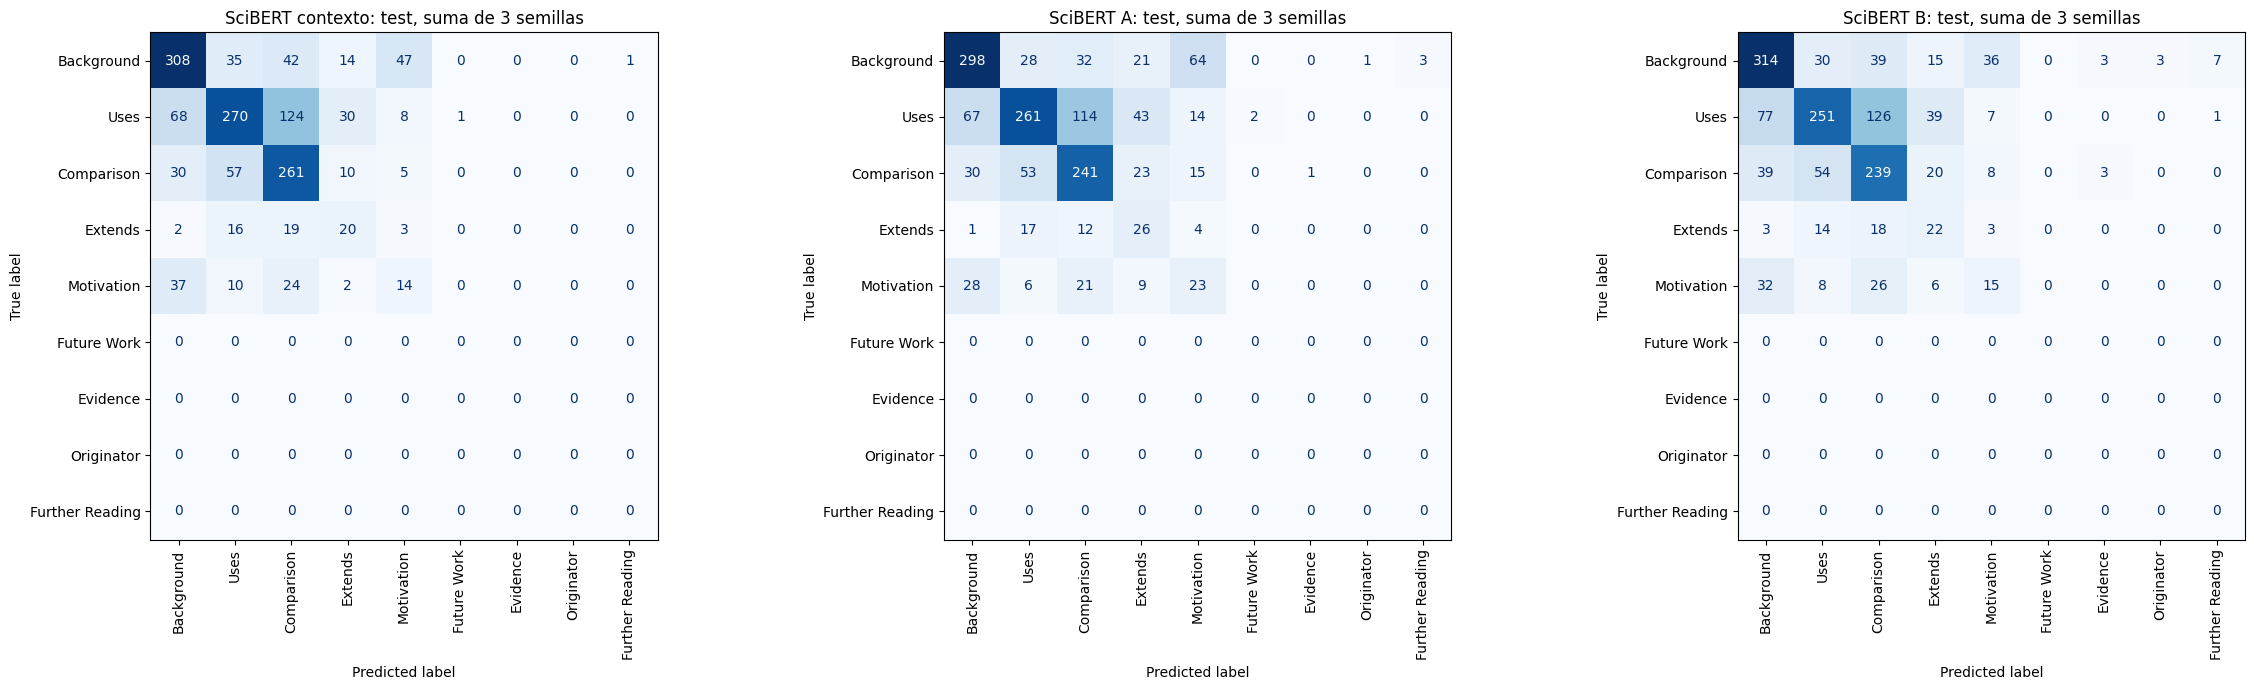

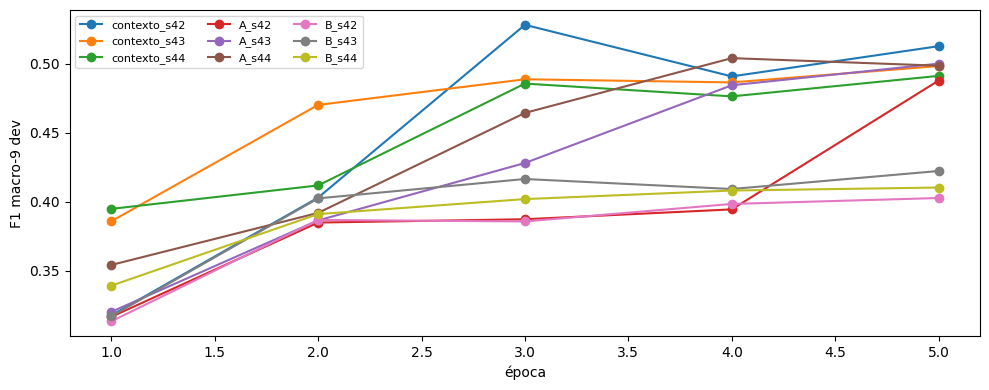

9254

In [13]:
fig, axes = plt.subplots(1, len(STRATEGIES), figsize=(8*len(STRATEGIES), 7))
for ax, strategy in zip(axes, STRATEGIES):
    cm = sum(confusion_matrix(ids['test'], p, labels=range(K)) for p in preds[strategy])
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=ax, cmap='Blues', colorbar=False, xticks_rotation=90)
    ax.set_title(f'SciBERT {strategy}: test, suma de {len(SEEDS)} semillas')
fig.tight_layout(); fig.savefig(OUT/'confusion.png', dpi=160, bbox_inches='tight'); plt.show()
fig, ax = plt.subplots(figsize=(10,4))
for key, history in histories.items():
    ax.plot([h['epoch'] for h in history], [h['dev_f1_macro_9'] for h in history], marker='o', label=key)
ax.set_xlabel('época'); ax.set_ylabel('F1 macro-9 dev'); ax.legend(ncol=3, fontsize=8)
fig.tight_layout(); fig.savefig(OUT/'dev_curves.png', dpi=160); plt.show()
(OUT/'results.json').write_text(json.dumps({'manifest':manifest,'runs':results.to_dict(orient='records'),'tfidf':tfidf_rows,'bootstrap':bootstrap.to_dict(orient='records')},indent=2,default=float),encoding='utf-8')

## Resultados

La época de cada corrida se eligió con F1 macro-9 en dev. Los valores son el promedio de 3 semillas sobre test.

| Modelo | Entrada adicional al contexto | F1 macro 9 etiquetas | F1 macro 5 clases presentes | Exactitud |
|:--|:--|--:|--:|--:|
| SciBERT contexto | Ninguna | 0,2649 | 0,4767 | 0,5988 |
| SciBERT A | Título y abstract del citado | 0,2648 | 0,4766 | 0,5823 |
| SciBERT B | Top-3 chunks del citado | 0,2585 | 0,4652 | 0,5768 |
| TF-IDF A | Título y abstract del citado | 0,1663 | 0,2993 | 0,3745 |
| TF-IDF B | Chunks del citado | 0,1286 | 0,2315 | 0,3045 |

Bootstrap pareado sobre test (10.000 remuestreos, diferencia en F1 macro-9):

| Comparación | Diferencia | IC 95% |
|:--|--:|:--|
| B frente a A | -0,0063 | -0,0183 a 0,0054 |
| A frente a contexto | -0,0001 | -0,0175 a 0,0173 |
| B frente a contexto | -0,0064 | -0,0220 a 0,0092 |
| A frente a TF-IDF A | 0,0985 | 0,0649 a 0,1307 |
| B frente a TF-IDF B | 0,1298 | 0,0992 a 0,1587 |

**Lectura del resultado.** Las tres entradas de SciBERT superan a TF-IDF, con intervalos por encima de cero. Agregar información del documento citado (A o B) no mejora frente a usar solo el contexto, y la diferencia entre B y A no es significativa.

**Alcance.** El test tiene 486 ejemplos y solo 5 de las 9 etiquetas. El F1 macro-9 cuenta en cero las 4 clases sin soporte. En B, cerca de la mitad de las entradas supera 512 tokens y se recorta el texto del citado.